# Noncommuting Lindblad dynamics with explicit channel splittings

The one-qubit model is $H=0.7X+0.3Z$, $L=\sqrt{0.8}|0\rangle\langle1|$, $t=1$, $\hbar=1$, and initial $|+i\rangle$. We split exact unitary Hamiltonian substeps from amplitude damping. Every damping substep uses an actual environment dilation and a fresh reset. The independently assembled $4\times4$ Liouvillian exponential is a bounded classical answer, not a quantum gate.

The source and figures are original MIT assets built on Qiskit 2.6.2 (Apache-2.0), NumPy and SciPy 1.18.1 (BSD-3-Clause). The chapter provides primary GKSL/product-formula citations. General interacting Lindblad algorithms and physical estimates remain planned.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit

root = Path.cwd()
if not (root / "src/openquantum/simulation/lindblad.py").exists() and (root.parent / "src/openquantum/simulation/lindblad.py").exists():
    root = root.parent
if (root / "src/openquantum/simulation/lindblad.py").exists():
    sys.path.insert(0, str(root / "src"))
    from openquantum.simulation import lindblad as lb
else:
    # Save downloaded lindblad.py and open_systems.py beside this notebook.
    sys.path.insert(0, str(root))
    import lindblad as lb

time, rate, hx, hz = 1.0, 0.8, 0.7, 0.3
reference = lb.exact_density(lb.input_density("plus_i"), time, rate, hx, hz)
print({name: float(np.trace(reference @ P).real) for name, P in lb.PAULI_MATRICES.items()})

{'X': -0.20630950942119075, 'Y': -0.22262616877448055, 'Z': 0.9112963723288878}


## An exact Hamiltonian substep

Set $\theta=\operatorname{atan2}(h_x,h_z)$ and $\omega=\sqrt{h_x^2+h_z^2}$. The matrix identity is $e^{-iH\delta}=R_Y(\theta)R_Z(2\omega\delta)R_Y(-\theta)$, so the chronological circuit begins with $-\theta$. There is no inner Hamiltonian product-formula error.

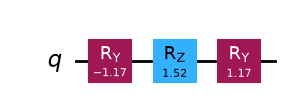

In [2]:
hamiltonian = QuantumCircuit(1)
lb.append_exact_hamiltonian(hamiltonian, 0, time, hx, hz)
hamiltonian.draw(output="mpl", fold=24)

## Positive-time splitting and environment reset

Lie applies H(dt) then D(dt) chronologically. Strang applies H(dt/2), D(dt), H(dt/2). Damping uses controlled RY and reverse CX, with a zero-input environment reset before each call. Intermediate resets discard previous correlations; the final environment record is ignored. No environment outcome is postselected. The diagram shows one symmetric step and final Z readout; the accuracy run uses 32 steps.

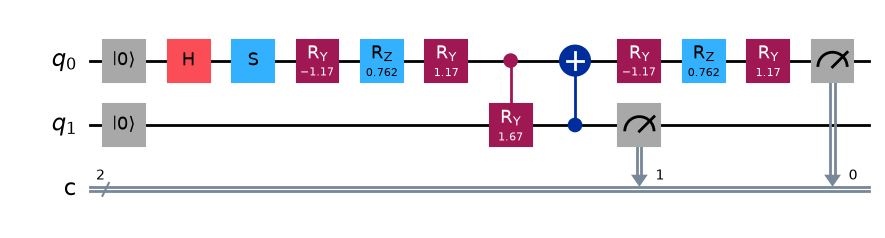

In [3]:
lb.build_lindblad_circuit(time, rate, hx, hz, steps=1, order=2, observable="Z").draw(output="mpl", fold=24)

## Reference convention and independent checks

Column vectorization uses $\operatorname{vec}(A\rho B)=(B^T\otimes A)\operatorname{vec}(\rho)$. The reference uses the standard dissipator $L\rho L^\dagger-\tfrac12\{L^\dagger L,\rho\}$. Four physical gate-prepared inputs reconstruct the numerical channel map. The reported superoperator spectral norm is the induced Hilbert–Schmidt $2\to2$ norm, separate from selected-input trace distance and diamond norm.

In [4]:
records = [lb.compare_lindblad(time, rate, hx, hz, steps=r, order=o) for o in (1, 2) for r in (1, 2, 4, 8, 16, 32, 64)]
rows = [{"order": item["order"], "steps": item["steps"], "trace distance": item["trace_distance"],
         "superoperator 2-to-2 error": item["superoperator_spectral_error"],
         "Z bias": item["observable_errors"]["Z"]} for item in records]
display(pd.DataFrame(rows).query("steps in [8, 16, 32]").reset_index(drop=True))
selected = lb.compare_lindblad(time, rate, hx, hz, steps=32, order=2)
assert selected["trace_distance"] < 0.005
assert min(r["minimum_eigenvalue"] for r in records) > -2e-12
assert max(abs(r["trace_real"]-1) for r in records) < 2e-12

,order,steps,trace distance,superoperator 2-to-2 error,Z bias
0,1,8,0.018879,0.046665,0.014049
1,1,16,0.009508,0.023367,0.007297
2,1,32,0.004771,0.011693,0.003717
3,2,8,0.000217,0.000678,0.000257
4,2,16,0.000054,0.000169,0.000064
5,2,32,0.000014,0.000042,0.000016


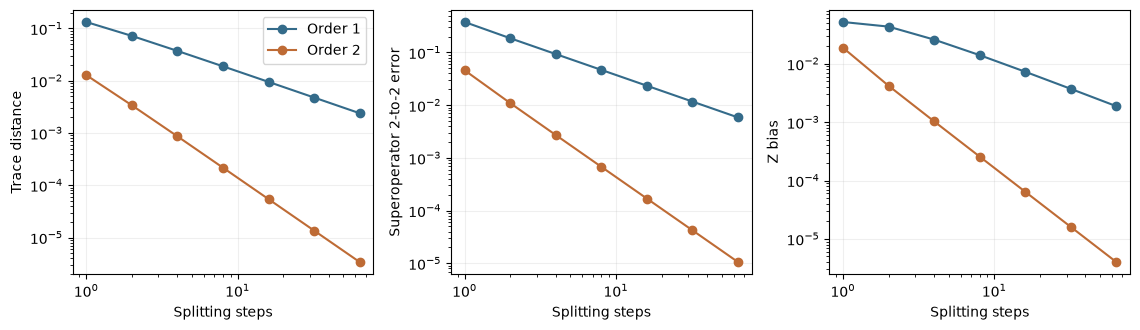

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4))
for order, color in ((1, "#346b8a"), (2, "#be6b35")):
    group = [r for r in records if r["order"] == order]
    metrics = [("trace_distance", "Trace distance"), ("superoperator_spectral_error", "Superoperator 2-to-2 error"), ("Z", "Z bias")]
    for ax, (key, label) in zip(axes, metrics):
        values = [r["observable_errors"][key] if key == "Z" else r[key] for r in group]
        ax.loglog([r["steps"] for r in group], values, "o-", color=color, label=f"Order {order}")
        ax.set(xlabel="Splitting steps", ylabel=label)
        ax.grid(alpha=.2)
axes[0].legend()
fig.tight_layout()
plt.show()

In [6]:
actual = lb.simulate_lindblad(time, rate, hx, hz, steps=32, order=2)
display(pd.DataFrame(actual, index=["0", "1"], columns=["0", "1"]))
print(f"Trace {np.trace(actual).real:.12f}; minimum eigenvalue {np.linalg.eigvalsh(actual).min():.12f}")
display(pd.DataFrame({"actual": selected["circuit_observables"], "exact": selected["exact_observables"], "absolute bias": selected["observable_errors"]}))

,0,1
0,0.955656+0.000000j,-0.103163+0.111321j
1,-0.103163-0.111321j,0.044344+0.000000j


Trace 1.000000000000; minimum eigenvalue 0.019731942897


,actual,exact,absolute bias
X,-0.206325,-0.206310,0.000016
Y,-0.222642,-0.222626,0.000015
Z,0.911312,0.911296,0.000016


## Full measured/reset ledger

The full trial includes one system initialization, 32 fresh environment initializations, all Hamiltonian/damping access, basis changes and final measurements. Environment resets after the first also discard previous environment states. X and Y readout require their own basis changes. The displayed counts remain before coherent rotation synthesis.

The 13,315-trial proposal applies to one fixed Z mean with sampling error 0.03 and statistical failure 0.005. It does not provide joint X/Y/Z or multiple-setting confidence. Splitting error, exact-angle Hamiltonian construction, finite representation, coherent synthesis and physical faults are separate contracts.

In [7]:
counts = {}
for observable in ("X", "Y", "Z"):
    circuit = lb.build_lindblad_circuit(time, rate, hx, hz, steps=32, order=2, observable=observable)
    compiled = lb.lower_to_rotation_basis(circuit)
    counts[observable] = dict(compiled.count_ops())
display(pd.DataFrame(counts).fillna(0).astype(int))
shots = lb.observable_shots()
print(f"One fixed Z mean: proposed {shots} complete independent trials")

,X,Y,Z
ry,97,97,98
cx,96,96,96
rz,66,66,65
reset,33,33,33
measure,2,2,2


One fixed Z mean: proposed 13315 complete independent trials


## Limits

Circuit generation is capped at 4,096 steps and an estimated 60,000 primitive operations. Density-matrix checks stop at 256 steps; the $4\times4$ exponential reference has an evolution-scale cap of 100. The quantum model remains one system and one reusable environment. Inputs beyond this scope require a separate implemented and checked generator.

Continuous-angle synthesis, physical reset/discard/readout timing, routing, factories, error correction and classical coefficient/readout wall time are excluded. The static shared physical adapter cannot directly model mid-circuit resets. Formal certificates and general interacting Lindblad simulation remain planned.